# 09 — Top-down MC distribution vs CAMS GFAS

**Biobío wildfire, 18 January 2026.** Companion to notebook 04, but instead of a
single point estimate this compares the **Monte-Carlo retrieval-error
distributions** (from notebooks 07 CO and 08 NOₓ) against the overpass-matched,
FRP-radius CAMS GFAS inventory. The 1σ spread of the top-down distribution is
shown explicitly.

Because the NOₓ distribution is strongly right-skewed (mean ≫ median), the **1σ
band is the [p16, p84] percentile interval** (robust), while the mean is reported
as the statistic closest to GFAS. Inputs are read from the canonical CSVs written
by 07/08 (`outputs/retrievals/0118/{co,nox}_distribution.csv`) and their member
logs (`outputs/error_mc/0118/`).


In [1]:
from __future__ import annotations
import os, glob, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')

_here = Path('.').resolve()
ROOT = next((p for p in [_here] + list(_here.parents)
             if (p / 'data').exists() and (p / 'src').exists()), None)
if ROOT is None:
    raise RuntimeError(f'Cannot locate project root from {_here}.')
os.chdir(ROOT)
print(f'Project root: {ROOT}')

from src.fire_clustering import load_modis_csv, frp_enclosing_radius
from src.inventory_helpers import gfas_integral

DATA_DIR = ROOT / 'data'
GFAS_DIR = DATA_DIR / 'CAMS_GFAS'
RETR_DIR = ROOT / 'outputs' / 'retrievals' / '0118'
MC_DIR   = ROOT / 'outputs' / 'error_mc' / '0118'
OUT_DIR  = ROOT / 'outputs' / 'inventory_comparison' / '0118'
OUT_DIR.mkdir(parents=True, exist_ok=True)

FIRE_LAT, FIRE_LON = -37.5484, -72.5545
FRP_FRACTION, FRP_CAP_KM = 0.99, 150.0
print('Config loaded.')

Project root: /Users/maperezc/Downloads/wildfires
Config loaded.


In [2]:
# ── FRP-defined integration radius (R99) — same as notebook 04 ───────────────
fires = load_modis_csv(DATA_DIR / 'fire_nrt_M-C61_723973.csv',
                       pd.Timestamp('2026-01-18'), pd.Timestamp('2026-01-18'),
                       lat_min=-66.75, lat_max=-7.0, lon_min=-103.0, lon_max=-43.25,
                       min_confidence=0, daytime_only=True, satellite=None)
R_FRP = frp_enclosing_radius(fires, FIRE_LAT, FIRE_LON, fraction=FRP_FRACTION, cap_km=FRP_CAP_KM)['radius_km']
print(f'FRP radius R99 = {R_FRP:.1f} km')

# ── GFAS at the FRP radius (overpass-matched) ────────────────────────────────
gfas_co  = gfas_integral(sorted(glob.glob(str(GFAS_DIR/'*cofire*.nc')))[0],  'cofire',  FIRE_LAT, FIRE_LON, R_FRP)
gfas_nox = gfas_integral(sorted(glob.glob(str(GFAS_DIR/'*noxfire*.nc')))[0], 'noxfire', FIRE_LAT, FIRE_LON, R_FRP)
# Report NOx on the NO mass basis: GFAS 'noxfire' is natively NOx as NO
# (Kaiser 2012 / Andreae & Merlet; AMT 18/3669/2025), so it needs no conversion;
# the top-down EMG side is native NO2 and is converted NO2->NO below.
M_NO_G_PER_MOL, M_NO2_G_PER_MOL = 30.006, 46.005
NO2_TO_NO = M_NO_G_PER_MOL / M_NO2_G_PER_MOL   # 0.6522
GFAS_CO_KG_S = gfas_co['total_kg_s']
GFAS_NOX_G_S = gfas_nox['total_kg_s'] * 1e3   # native NO basis (g NO/s)
print(f'GFAS @ R99={R_FRP:.0f} km (valid {gfas_co["valid_time"]}):  CO = {GFAS_CO_KG_S:.1f} kg/s   NOx = {GFAS_NOX_G_S:.0f} g/s')

FRP radius R99 = 142.3 km
GFAS @ R99=142 km (valid 2026-01-18 18:00:00):  CO = 331.9 kg/s   NOx = 10871 g/s


In [3]:
# ── Load the top-down MC distributions (canonical CSVs from 07 & 08) ─────────
co_d  = pd.read_csv(RETR_DIR / 'co_distribution.csv',  index_col=0)['value']
nox_d = pd.read_csv(RETR_DIR / 'nox_distribution.csv', index_col=0)['value']

def _f(s, k): return float(s[k])
co_stats  = {k: _f(co_d, k)  for k in ['mean','std','median','p16','p84','p2_5','p97_5']}
nox_stats = {k: _f(nox_d, k) * NO2_TO_NO for k in ['mean','std','median','p16','p84','p2_5','p97_5']}   # NO2 -> NO
co_stats['n']  = int(float(co_d['n']));  nox_stats['n'] = int(float(nox_d['n']))

# member arrays (for the histograms + GFAS percentile)
co_members  = pd.read_csv(MC_DIR / 'co_error_members.csv')['flux_kgs'].to_numpy()
nox_members = pd.read_csv(MC_DIR / 'nox_error_members.csv')['E_nox_g_per_s'].to_numpy()
co_members  = co_members[np.isfinite(co_members)]
nox_members = nox_members[np.isfinite(nox_members)] * NO2_TO_NO   # g NO2/s -> g NO/s

# percentile at which GFAS falls within each top-down distribution
co_gfas_pct  = float((co_members  < GFAS_CO_KG_S).mean() * 100.0)
nox_gfas_pct = float((nox_members < GFAS_NOX_G_S).mean() * 100.0)
print(f'CO  : top-down mean={co_stats["mean"]:.0f} kg/s, 1sigma[{co_stats["p16"]:.0f},{co_stats["p84"]:.0f}] '
      f'| GFAS={GFAS_CO_KG_S:.0f} kg/s -> GFAS at {co_gfas_pct:.0f}th pct of top-down')
print(f'NOx : top-down mean={nox_stats["mean"]:.0f} g/s, 1sigma[{nox_stats["p16"]:.0f},{nox_stats["p84"]:.0f}] '
      f'| GFAS={GFAS_NOX_G_S:.0f} g/s -> GFAS at {nox_gfas_pct:.0f}th pct of top-down')

CO  : top-down mean=1258 kg/s, 1sigma[941,1557] | GFAS=332 kg/s -> GFAS at 0th pct of top-down
NOx : top-down mean=4805 g/s, 1sigma[3433,5675] | GFAS=10871 g/s -> GFAS at 100th pct of top-down


In [4]:
# ── Comparison table: distribution statistics vs GFAS ────────────────────────
rows = []
for sp, st, gfas, unit, pct in [
    ('CO',  co_stats,  GFAS_CO_KG_S, 'kg/s', co_gfas_pct),
    ('NOx', nox_stats, GFAS_NOX_G_S, 'g/s',  nox_gfas_pct)]:
    rows.append({
        'species': sp, 'units': unit, 'n_mc': st['n'],
        'topdown_mean': round(st['mean'],2), 'topdown_median': round(st['median'],2),
        'topdown_p16': round(st['p16'],2), 'topdown_p84': round(st['p84'],2),
        'gfas': round(gfas,2),
        'mean_over_gfas':   round(st['mean']/gfas, 3),
        'median_over_gfas': round(st['median']/gfas, 3),
        'gfas_percentile_in_topdown': round(pct,1),
    })
cmp_df = pd.DataFrame(rows)
cmp_df.to_csv(OUT_DIR / 'comparison_mc_summary.csv', index=False)
print(cmp_df.to_string(index=False))

species units  n_mc  topdown_mean  topdown_median  topdown_p16  topdown_p84     gfas  mean_over_gfas  median_over_gfas  gfas_percentile_in_topdown
     CO  kg/s   287       1257.59         1273.35       941.16      1556.96   331.89           3.789             3.837                         0.0
    NOx   g/s   285       4805.41         4895.00      3432.50      5675.24 10871.34           0.442             0.450                        99.6


Saved comparison_mc_histograms.png -> /Users/maperezc/Downloads/wildfires/outputs/inventory_comparison/0118


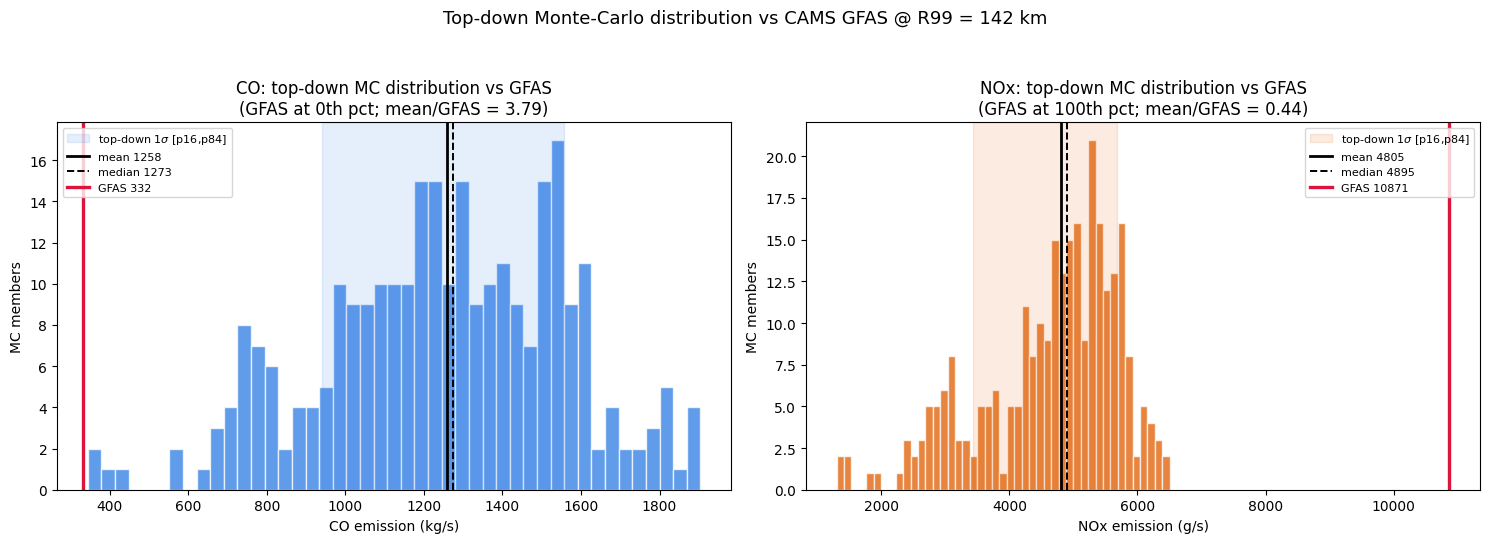

In [5]:
# ── Figure 1: MC distributions with 1sigma band and GFAS overlaid ────────────
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, sp, members, st, gfas, unit, col in [
    (axes[0], 'CO',  co_members,  co_stats,  GFAS_CO_KG_S, 'kg/s', '#2c7be5'),
    (axes[1], 'NOx', nox_members, nox_stats, GFAS_NOX_G_S, 'g/s',  '#e05c00')]:
    clip = np.percentile(members, 99)               # trim long upper tail for readability
    ax.hist(members[members <= clip], bins=45, color=col, alpha=0.75, edgecolor='white')
    ax.axvspan(st['p16'], st['p84'], color=col, alpha=0.12, label='top-down 1$\sigma$ [p16,p84]')
    ax.axvline(st['mean'],   color='k', lw=2,           label=f"mean {st['mean']:.0f}")
    ax.axvline(st['median'], color='k', lw=1.4, ls='--', label=f"median {st['median']:.0f}")
    ax.axvline(gfas, color='crimson', lw=2.4, label=f'GFAS {gfas:.0f}')
    ax.set(xlabel=f'{sp} emission ({unit})', ylabel='MC members',
           title=f'{sp}: top-down MC distribution vs GFAS\n(GFAS at {(members<gfas).mean()*100:.0f}th pct; '
                 f'mean/GFAS = {st["mean"]/gfas:.2f})')
    ax.legend(fontsize=8)
fig.suptitle(f'Top-down Monte-Carlo distribution vs CAMS GFAS @ R99 = {R_FRP:.0f} km', fontsize=13)
fig.tight_layout(rect=[0,0,1,0.94])
fig.savefig(OUT_DIR / 'comparison_mc_histograms.png', dpi=140, bbox_inches='tight')
print(f'Saved comparison_mc_histograms.png -> {OUT_DIR}')

Saved comparison_mc_errorbars.png, comparison_mc_summary.csv -> /Users/maperezc/Downloads/wildfires/outputs/inventory_comparison/0118


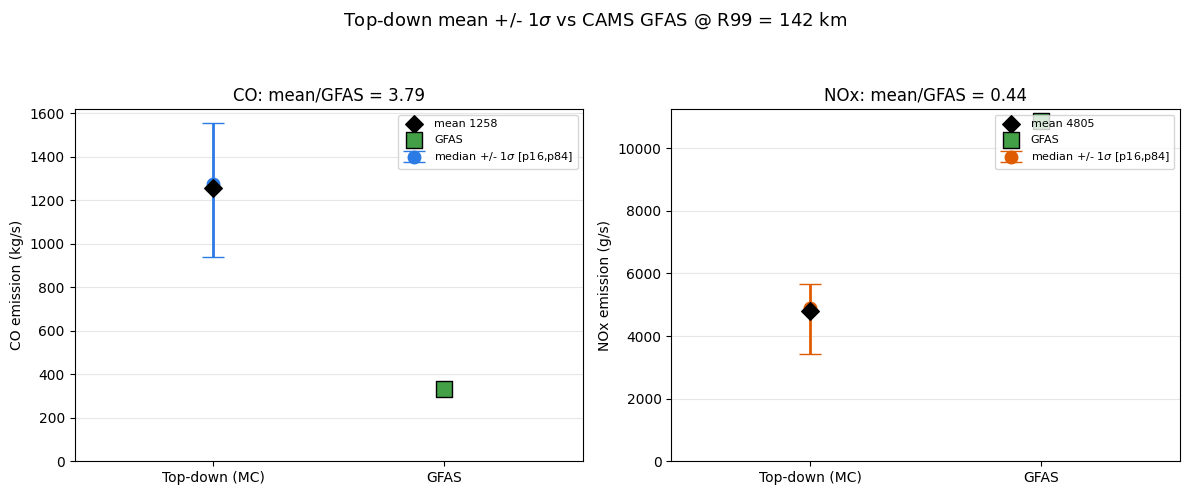

In [6]:
# ── Figure 2: mean +/- 1sigma (p16,p84) vs GFAS ──────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, sp, st, gfas, unit, col in [
    (axes[0], 'CO',  co_stats,  GFAS_CO_KG_S, 'kg/s', '#2c7be5'),
    (axes[1], 'NOx', nox_stats, GFAS_NOX_G_S, 'g/s',  '#e05c00')]:
    yerr = [[st['median'] - st['p16']], [st['p84'] - st['median']]]   # 1sigma band around median
    ax.errorbar([0], [st['median']], yerr=yerr, fmt='o', ms=9, color=col, capsize=8,
                lw=2, label="median +/- 1$\sigma$ [p16,p84]")
    ax.scatter([0], [st['mean']], marker='D', s=80, color='k', zorder=6, label=f"mean {st['mean']:.0f}")
    ax.scatter([1], [gfas], marker='s', s=120, color='#43A047', edgecolor='k', zorder=5, label='GFAS')
    ax.set_xticks([0,1]); ax.set_xticklabels(['Top-down (MC)', 'GFAS'])
    ax.set_xlim(-0.6, 1.6); ax.set_ylim(bottom=0)
    ax.set_ylabel(f'{sp} emission ({unit})')
    ax.set_title(f'{sp}: mean/GFAS = {st["mean"]/gfas:.2f}')
    ax.grid(axis='y', alpha=0.3); ax.legend(fontsize=8, loc='upper right')
fig.suptitle(f'Top-down mean +/- 1$\sigma$ vs CAMS GFAS @ R99 = {R_FRP:.0f} km', fontsize=13)
fig.tight_layout(rect=[0,0,1,0.93])
fig.savefig(OUT_DIR / 'comparison_mc_errorbars.png', dpi=140, bbox_inches='tight')
print(f'Saved comparison_mc_errorbars.png, comparison_mc_summary.csv -> {OUT_DIR}')

Saved comparison_mc_bars_fixed_vs_dist.png -> /Users/maperezc/Downloads/wildfires/outputs/inventory_comparison/0118
  CO : fixed=1363, median=1273, [p16,p84]=[941,1557] kg/s
  NOx: fixed=8415, median=4895, [p16,p84]=[3433,5675] g/s


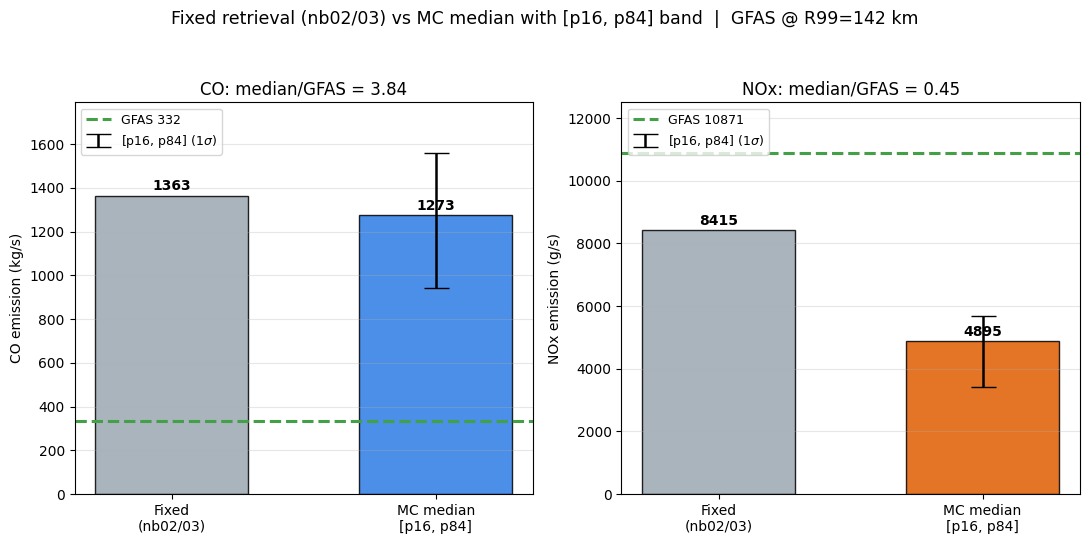

In [7]:
# ── Figure 3: fixed retrieval vs MC median with [p16, p84] band ──────────────
# Fixed-parameter point estimates from the canonical retrievals (notebooks 02/03)
co_pt  = float(pd.read_csv(RETR_DIR/'co_retrieval.csv',  index_col=0)['value']['co_flux_variant_kg_s'])
nox_pt = float(pd.read_csv(RETR_DIR/'nox_retrieval.csv', index_col=0)['value']['nox_flux_g_s'])

fig, axes = plt.subplots(1, 2, figsize=(11, 5.5))
for ax, sp, st, pt, gfas, unit, col in [
    (axes[0], 'CO',  co_stats,  co_pt,  GFAS_CO_KG_S, 'kg/s', '#2c7be5'),
    (axes[1], 'NOx', nox_stats, nox_pt, GFAS_NOX_G_S, 'g/s',  '#e05c00')]:
    labels = ['Fixed\n(nb02/03)', 'MC median\n[p16, p84]']
    vals   = [pt, st['median']]
    x = np.arange(2)
    ax.bar(x, vals, color=['#9aa7b1', col], alpha=0.85, edgecolor='k', width=0.58)
    # [p16, p84] band as asymmetric error bars around the median (median is inside the band)
    p16, p84 = st['p16'], st['p84']
    ax.errorbar([1], [st['median']], yerr=[[st['median']-p16], [p84-st['median']]],
                fmt='none', ecolor='k', capsize=9, lw=1.8, label='[p16, p84] (1$\sigma$)')
    for xi, v in zip(x, vals):
        ax.text(xi, v*1.01, f'{v:.0f}', ha='center', va='bottom', fontsize=10, fontweight='bold')
    ax.axhline(gfas, color='#43A047', ls='--', lw=2.2, label=f'GFAS {gfas:.0f}')
    ax.set_xticks(x); ax.set_xticklabels(labels)
    ax.set_ylabel(f'{sp} emission ({unit})')
    ax.set_ylim(0, max(st['median'], p84, gfas, pt)*1.15)
    ax.set_title(f'{sp}: median/GFAS = {st["median"]/gfas:.2f}')
    ax.grid(axis='y', alpha=0.3); ax.legend(fontsize=9, loc='upper left')
fig.suptitle(f'Fixed retrieval (nb02/03) vs MC median with [p16, p84] band  |  GFAS @ R99={R_FRP:.0f} km', fontsize=12.5)
fig.tight_layout(rect=[0,0,1,0.94])
fig.savefig(OUT_DIR / 'comparison_mc_bars_fixed_vs_dist.png', dpi=140, bbox_inches='tight')
print(f'Saved comparison_mc_bars_fixed_vs_dist.png -> {OUT_DIR}')
print(f'  CO : fixed={co_pt:.0f}, median={co_stats["median"]:.0f}, [p16,p84]=[{co_stats["p16"]:.0f},{co_stats["p84"]:.0f}] kg/s')
print(f'  NOx: fixed={nox_pt:.0f}, median={nox_stats["median"]:.0f}, [p16,p84]=[{nox_stats["p16"]:.0f},{nox_stats["p84"]:.0f}] g/s')

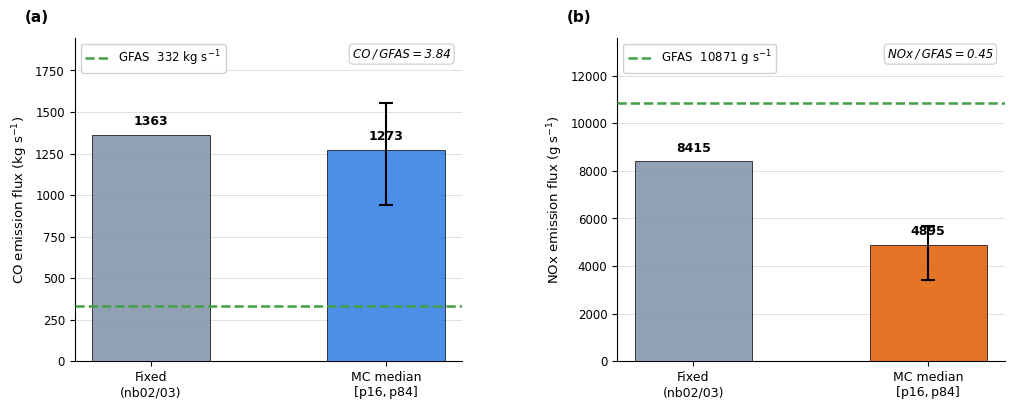

Saved -> /Users/maperezc/Downloads/wildfires/outputs/inventory_comparison/0118/comparison_mc_bars_fixed_vs_dist.png
  CO : fixed=1363, median=1273, [p16,p84]=[941,1557] kg/s
  NOx: fixed=8415, median=4895, [p16,p84]=[3433,5675] g/s


In [8]:
# ── Figure 3: fixed retrieval vs MC median with [p16, p84] band ──────────────
co_pt  = float(pd.read_csv(RETR_DIR/'co_retrieval.csv',  index_col=0)['value']['co_flux_variant_kg_s'])
nox_pt = float(pd.read_csv(RETR_DIR/'nox_retrieval.csv', index_col=0)['value']['nox_flux_g_s'])

COLOR_FIXED = '#7f8fa6'
COLOR_GFAS  = '#43A047'

fig, axes = plt.subplots(1, 2, figsize=(12.0, 4.2))
fig.subplots_adjust(wspace=0.40)

for ax, sp, st, pt, gfas, unit, col, plabel in zip(
    axes,
    ['CO',   'NOx'],
    [co_stats,   nox_stats],
    [co_pt,      nox_pt],
    [GFAS_CO_KG_S, GFAS_NOX_G_S],
    [r'kg s$^{-1}$', r'g s$^{-1}$'],
    ['#2c7be5',  '#e05c00'],
    ['(a)',      '(b)'],
):
    p16, p84  = st['p16'], st['p84']
    vals      = [pt, st['median']]
    x         = np.arange(2)
    ylim_top  = max(pt, p84, gfas) * 1.25

    # bars
    ax.bar(x, vals, color=[COLOR_FIXED, col], alpha=0.85,
           edgecolor='k', linewidth=0.6, width=0.50, zorder=3)

    # [p16, p84] asymmetric error bars on MC bar
    ax.errorbar([1], [st['median']],
                yerr=[[st['median'] - p16], [p84 - st['median']]],
                fmt='none', ecolor='k', elinewidth=1.5,
                capsize=5, capthick=1.5, zorder=5)

    # GFAS reference line
    ax.axhline(gfas, color=COLOR_GFAS, ls='--', lw=1.8, zorder=4,
               label=f'GFAS  {gfas:.0f} {unit}')

    # value labels above bars
    for xi, v in zip(x, vals):
        ax.text(xi, v + ylim_top * 0.02,
                f'{v:.0f}', ha='center', va='bottom',
                fontsize=9, fontweight='bold')

    # MC / GFAS ratio text box
    ratio = st['median'] / gfas
    ratio_str = f'\u00d7{ratio:.2f}' if ratio >= 1 else f'\u2212{(1-ratio)*100:.0f}\u202f%'
    ax.text(0.97, 0.97, f'{sp}\u2009/\u2009GFAS\u2009=\u2009{ratio:.2f}',
            transform=ax.transAxes, ha='right', va='top',
            fontsize=8.5, style='italic',
            bbox=dict(boxstyle='round,pad=0.3', fc='white',
                      ec='0.75', lw=0.7, alpha=0.92))

    # axes formatting
    ax.set_xticks(x)
    ax.set_xticklabels(['Fixed\n(nb02/03)', 'MC median\n[p16,\u2009p84]'], fontsize=9)
    ax.set_ylabel(f'{sp} emission flux ({unit})', fontsize=9.5)
    ax.set_ylim(0, ylim_top)
    ax.tick_params(axis='y', labelsize=8.5)
    ax.spines[['top', 'right']].set_visible(False)
    ax.set_axisbelow(True)
    ax.grid(axis='y', color='0.88', linewidth=0.7)
    ax.legend(loc='upper left', fontsize=8.5,
              frameon=True, framealpha=0.9, edgecolor='0.80')

    # panel label
    ax.text(-0.13, 1.04, plabel, transform=ax.transAxes,
            fontsize=11, fontweight='bold', va='bottom', ha='left')

fig.savefig(OUT_DIR / 'comparison_mc_bars_fixed_vs_dist.png', dpi=200, bbox_inches='tight')
plt.show()
print(f'Saved -> {OUT_DIR / "comparison_mc_bars_fixed_vs_dist.png"}')
print(f'  CO : fixed={co_pt:.0f}, median={co_stats["median"]:.0f}, '
      f'[p16,p84]=[{co_stats["p16"]:.0f},{co_stats["p84"]:.0f}] kg/s')
print(f'  NOx: fixed={nox_pt:.0f}, median={nox_stats["median"]:.0f}, '
      f'[p16,p84]=[{nox_stats["p16"]:.0f},{nox_stats["p84"]:.0f}] g/s')

## Summary

Comparing the **top-down Monte-Carlo distributions** (07/08) against the
overpass-matched GFAS inventory at the FRP-defined radius makes the inventory's
position explicit relative to the retrieval uncertainty:

- **CO**: GFAS sits in the lower tail of the top-down distribution (below p16),
  i.e. the top-down CO remains well above GFAS even accounting for retrieval error.
- **NOₓ**: GFAS lies near the upper edge of the 1σ band; the distribution **mean**
  is the statistic closest to GFAS, while the (skewed) median sits well below it.

The 1σ band is the [p16, p84] percentile interval because the NOₓ distribution is
strongly right-skewed (mean ≫ median). All inputs are read from the canonical
07/08 CSVs, so re-running 07/08 propagates automatically into this comparison.
